### In this notebook I tried a different approach with combining the datasets and did some EDA with the whole set

In [1]:
# IMPORTS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_auc_score

In [2]:
# Combining the datasets together with a new column for run_id and road_id

dfA1 = pd.read_csv("../dataset/cleaned/Iisingintie0.csv")
dfA2 = pd.read_csv("../dataset/cleaned/Iisingintie1.csv")
dfA3 = pd.read_csv("../dataset/cleaned/Iisingintie2.csv")

dfB1 = pd.read_csv("../dataset/cleaned/Sinetansalmentie0.csv")
dfB2 = pd.read_csv("../dataset/cleaned/Sinetansalmentie1.csv")
dfB3 = pd.read_csv("../dataset/cleaned/Sinetansalmentie2.csv")
dfB4 = pd.read_csv("../dataset/cleaned/Sinetansalmentie3.csv")

dfC1 = pd.read_csv("../dataset/cleaned/Kaittiaisentie0.csv")


runs = {
    "A1": (dfA1, "A"), "A2": (dfA2, "A"), "A3": (dfA3, "A"),
    "B1": (dfB1, "B"), "B2": (dfB2, "B"), "B3": (dfB3, "B"), "B4": (dfB4, "B"),
    "C1": (dfC1, "C"),
}

df = pd.concat(
    [d.assign(run_id=rid, road_id=road) for rid, (d, road) in runs.items()],
    ignore_index=True,
)

In [3]:
len(df)

415760

In [4]:
run_names = list(runs.keys())
print(run_names)

['A1', 'A2', 'A3', 'B1', 'B2', 'B3', 'B4', 'C1']


In [5]:
df

,Timer(ms),Loc(m),CElev(m),Roll(deg),Pitch(deg),Yaw(deg),AccX,AccY,AccZ,GyrX,GyrY,GyrZ,Speed_kmh,Frostbumps,run_id,road_id
0,45493158.5,3850.503,106.794,1.1747,-3.0780,141.0204,1.53481,0.05712,9.58495,0.03196,0.00072,-0.00300,62.1936,0,A1,A
1,45493161.0,3850.546,106.794,1.2245,-3.0428,141.1350,1.51066,-0.04196,10.50449,0.02201,0.00598,-0.01390,62.2044,0,A1,A
2,45493163.5,3850.589,106.794,1.2281,-3.0428,141.1349,1.15831,0.37071,10.76888,0.01993,0.00065,-0.00562,62.2116,0,A1,A
3,45493166.0,3850.633,106.794,1.2330,-3.0430,141.1341,1.03301,0.31102,11.42271,0.02887,-0.00077,-0.01012,62.2224,0,A1,A
4,45493168.5,3850.676,106.794,1.2363,-3.0431,141.1329,0.99574,-0.37334,11.76243,0.01783,0.00007,-0.01306,62.2332,0,A1,A
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
415755,48394974.5,3177.920,120.720,-0.9675,-3.4588,-47.2120,-0.68158,0.08021,9.89489,-0.02289,-0.00231,0.00294,14.8608,0,C1,C
415756,48394977.0,3177.920,120.720,-0.9701,-3.4581,-47.2115,-0.70976,0.04869,9.84995,-0.02335,0.00517,-0.00078,14.8464,0,C1,C
415757,48394979.5,3177.920,120.720,-0.9719,-3.4568,-47.2122,-0.77364,0.00735,9.95328,-0.01821,0.01022,-0.00917,14.8356,0,C1,C
415758,48394982.0,3177.920,120.720,-0.9744,-3.4563,-47.2120,-0.78316,0.02913,9.89511,-0.02315,0.00434,-0.00332,14.8212,0,C1,C


In [6]:
feature_cols = ["AccX", "AccY", "AccZ", "GyrX", "GyrY", "GyrZ",
                "Pitch(deg)", "Roll(deg)", "Speed_kmh"]


In [7]:
# This code makes row windows of the data, with a given window size and stride. It returns the X and y values for each window.

# def make_row_windows(run_df, win=100, stride=20):
#     run_df = run_df.sort_values("Timer(ms)")
#     X = run_df[feature_cols].to_numpy(np.float32)
#     y = run_df["Frostbumps"].to_numpy()

#     X_clips, y_clips = [], []
#     for start in range(0, len(X) - win + 1, stride):
#         end = start + win
#         X_clips.append(X[start:end])
#         y_clips.append(y[start:end].max())

#     return np.array(X_clips), np.array(y_clips)

In [8]:
def make_row_windows(run_df, win=0, stride=0, min_percentage=0.1):
    run_df = run_df.sort_values("Timer(ms)")

    X = run_df[feature_cols].to_numpy(np.float32)
    y = run_df["Frostbumps"].to_numpy()

    X_clips, y_clips = [], []

    for start in range(0, len(X) - win + 1, stride):
        end = start + win

        X_clips.append(X[start:end])

        bump_percentage = y[start:end].mean()
        y_clips.append(int(bump_percentage >= min_percentage))

    return np.array(X_clips), np.array(y_clips)

In [9]:
def get_clips(run_names):
    all_X, all_y = [], []
    for name in run_names:
        one_run = df[df["run_id"] == name]
        X, y = make_row_windows(one_run, win=100, stride=80)
        all_X.append(X)
        all_y.append(y)
    return np.concatenate(all_X), np.concatenate(all_y)

In [10]:
# Checking the number of windows per run

for run in ["A1", "A2", "A3", "B1", "B2", "B3", "B4", "C1"]:
    X, y = get_clips([run])

    print(
        f"{run}: {len(y)} windows, "
        f"{y.mean():.1%} positive"
    )

A1: 710 windows, 22.1% positive
A2: 943 windows, 21.1% positive
A3: 1433 windows, 19.2% positive
B1: 119 windows, 39.5% positive
B2: 162 windows, 26.5% positive
B3: 163 windows, 32.5% positive
B4: 226 windows, 35.0% positive
C1: 1436 windows, 5.1% positive


In [11]:
# Training, validation, test splits

Xtr, ytr = get_clips(["A2", "B1", "B3", "B2", "A3"])
Xva, yva = get_clips(["A1", "B4"])
Xte, yte = get_clips(["C1"])

print(Xtr.shape, Xva.shape, Xte.shape)
print(ytr.mean(), yva.mean(), yte.mean())

(2820, 100, 9) (936, 100, 9) (1436, 100, 9)
0.21879432624113476 0.25213675213675213 0.05083565459610028


In [12]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

n_features = Xtr.shape[2]

Xtr_scaled = scaler.fit_transform(
    Xtr.reshape(-1, n_features)
).reshape(Xtr.shape)

Xva_scaled = scaler.transform(
    Xva.reshape(-1, n_features)
).reshape(Xva.shape)

Xte_scaled = scaler.transform(
    Xte.reshape(-1, n_features)
).reshape(Xte.shape)

In [13]:
from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([
    layers.Input(shape=Xtr.shape[1:]),
    layers.Conv1D(16, 7, padding="same", activation="relu"),
    layers.MaxPooling1D(2),
    layers.Conv1D(32, 5, padding="same", activation="relu"),
    layers.GlobalMaxPooling1D(),
    layers.Dropout(0.3),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])

optimizer = keras.optimizers.Adam(learning_rate=0.001)

model.compile(optimizer="adam", loss="binary_crossentropy",
              metrics=[keras.metrics.AUC(curve="PR", name="pr_auc")])

w = min((ytr == 0).sum() / max((ytr == 1).sum(), 1), 20)

history = model.fit(Xtr, ytr, validation_data=(Xva, yva),
          epochs=100, batch_size=32,
          class_weight={0: 1.0, 1: float(w)},
          callbacks=[keras.callbacks.EarlyStopping(
              monitor="val_loss", patience=10, restore_best_weights=True)])



Epoch 1/100
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1.9020 - pr_auc: 0.2193 - val_loss: 1.1769 - val_pr_auc: 0.2338
Epoch 2/100
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.1327 - pr_auc: 0.2496 - val_loss: 0.6533 - val_pr_auc: 0.2661
Epoch 3/100
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0780 - pr_auc: 0.2824 - val_loss: 1.1812 - val_pr_auc: 0.2397
Epoch 4/100
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0774 - pr_auc: 0.2581 - val_loss: 0.7858 - val_pr_auc: 0.2124
Epoch 5/100
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0539 - pr_auc: 0.2857 - val_loss: 0.9124 - val_pr_auc: 0.2545
Epoch 6/100
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0513 - pr_auc: 0.2888 - val_loss: 0.8399 - val_pr_auc: 0.2829
Epoch 7/100
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0312 - pr_auc: 0.3429 - val_loss: 0.6821 - val_pr_auc: 0.2870
Epoch 8/100
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0357 - pr_auc: 0.3459 - val_loss: 1.0912 - val_pr_auc: 0.2642
Epoch 9/100
89/8

In [14]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 100, 16)        │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 50, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 50, 32)         │         2,592 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 32)             │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,485 (48.77 KB)

 Trainable params: 4,161 (16.25 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 8,324 (32.52 KB)

In [15]:
from sklearn.metrics import average_precision_score, roc_auc_score

# Get predicted probabilities
y_pred_proba = model.predict(Xte).ravel()

# Calculate AUC scores
pr_auc = average_precision_score(yte, y_pred_proba)
roc_auc = roc_auc_score(yte, y_pred_proba)

print(f"PR-AUC:  {pr_auc:.4f}")
print(f"ROC-AUC: {roc_auc:.4f}")

45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
PR-AUC:  0.0861
ROC-AUC: 0.5731


<Axes: >

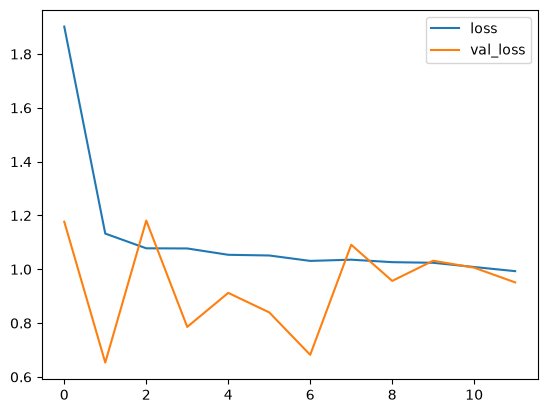

In [16]:
loss_df = pd.DataFrame(model.history.history)
loss_df[['loss', 'val_loss']].plot()

In [17]:
print("Training:", len(ytr), ytr.mean())
print("Validation:", len(yva), yva.mean())
print("Test:", len(yte), yte.mean())

Training: 2820 0.21879432624113476
Validation: 936 0.25213675213675213
Test: 1436 0.05083565459610028


In [18]:
# compare the final model loss/accuracy/evaluation values
# the values should match mostly
print("Test data evaluation:")
print(model.evaluate(Xte, yte, verbose=0))
print("\nTrain data evaluation:")
print(model.evaluate(Xtr, ytr, verbose=0))

Test data evaluation:
[0.6028959155082703, 0.08200443536043167]

Train data evaluation:
[0.6159347891807556, 0.32640618085861206]


45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 959us/step


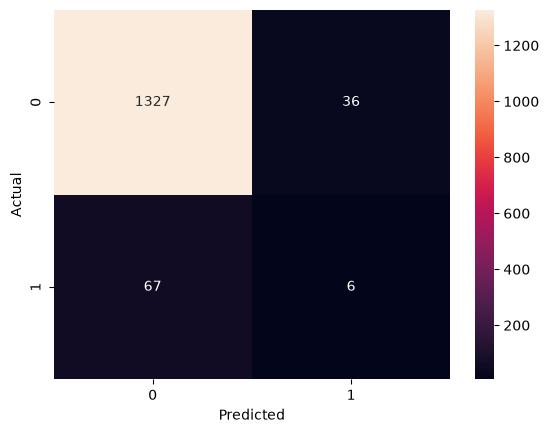

In [19]:
test_predictions = model.predict(Xte).ravel()

test_predictions = (test_predictions >= 0.50).astype(int)


# confusion matrix
import seaborn as sns
sns.heatmap(confusion_matrix(yte, test_predictions), annot=True, fmt='g')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()



In [20]:
from sklearn.metrics import confusion_matrix, classification_report

y_pred = (model.predict(Xte).ravel() >= 0.5).astype(int)

print(confusion_matrix(yte, y_pred))
print(classification_report(yte, y_pred))

acc = accuracy_score(yte, test_predictions)
print("\nModel overall accuracy: {:.2f}%".format(acc * 100))

45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 753us/step
[[1327   36]
 [  67    6]]
              precision    recall  f1-score   support

           0       0.95      0.97      0.96      1363
           1       0.14      0.08      0.10        73

    accuracy                           0.93      1436
   macro avg       0.55      0.53      0.53      1436
weighted avg       0.91      0.93      0.92      1436


Model overall accuracy: 92.83%


In [22]:
y_prob = model.predict(Xte).ravel()

print("Actual frost bumps:", np.sum(yte == 1))
print("Predicted frost bumps:", np.sum(y_prob >= 0.5))

print("\nProbabilities for actual frost bumps:")
print(y_prob[yte == 1])

45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 798us/step
Actual frost bumps: 73
Predicted frost bumps: 42

Probabilities for actual frost bumps:
[0.47559497 0.45723987 0.47042066 0.50099134 0.5225581  0.44124958
 0.48915267 0.479709   0.49799436 0.43673536 0.4219803  0.41878185
 0.42143792 0.43003014 0.4618702  0.42642525 0.42236897 0.43084562
 0.4108315  0.4356841  0.43215376 0.421387   0.45632204 0.4694503
 0.43901822 0.4244131  0.43758696 0.4233059  0.45584062 0.45144477
 0.44015443 0.42653623 0.46615726 0.44006377 0.46100062 0.46423253
 0.4645883  0.4726355  0.49700075 0.5121813  0.45162487 0.43191504
 0.46342805 0.47405663 0.43842152 0.44118136 0.45378706 0.4748239
 0.4459749  0.43326968 0.4698735  0.5075904  0.4795416  0.4686858
 0.44048542 0.49980527 0.47956604 0.49149418 0.44087607 0.4525794
 0.42654768 0.51174307 0.5286495  0.44475865 0.45741042 0.47299585
 0.4560211  0.42527747 0.45245585 0.4632244  0.451792   0.46870315
 0.49964517]


In [23]:
# runs = ["A1", "A2", "A3", "B1", "B2", "B3", "B4"]

# test_run = "A1"
# val_run = "A2"
# train_runs = [r for r in runs if r not in (test_run, val_run)]

# print(train_runs)

In [24]:
# def build_model(input_shape):
#     model = keras.Sequential([
#         layers.Input(shape=input_shape),
#         layers.Conv1D(8, 7, padding="same", activation="relu"),
#         layers.MaxPooling1D(2),
#         layers.Conv1D(16, 5, padding="same", activation="relu"),
#         layers.GlobalMaxPooling1D(),
#         layers.Dropout(0.3),
#         layers.Dense(16, activation="relu"),
#         layers.Dense(1, activation="sigmoid"),
#     ])
#     model.compile(optimizer="adam", loss="binary_crossentropy")
#     return model

In [25]:
# scores = {}

# for i, test_run in enumerate(runs):
#     val_run = runs[(i + 1) % len(runs)]
#     train_runs = [r for r in runs if r not in (test_run, val_run)]

#     Xtr, ytr = get_clips(train_runs)
#     Xva, yva = get_clips([val_run])
#     Xte, yte = get_clips([test_run])

#     n_features = Xtr.shape[-1]
#     scaler = StandardScaler().fit(Xtr.reshape(-1, n_features))
#     Xtr = scaler.transform(Xtr.reshape(-1, n_features)).reshape(Xtr.shape)
#     Xva = scaler.transform(Xva.reshape(-1, n_features)).reshape(Xva.shape)
#     Xte = scaler.transform(Xte.reshape(-1, n_features)).reshape(Xte.shape)

#     keras.backend.clear_session()
#     model = build_model(Xtr.shape[1:])

#     model.fit(
#         Xtr, ytr,
#         validation_data=(Xva, yva),
#         epochs=30,
#         batch_size=32,
#         class_weight={0: 1.0, 1: 3.0},
#         verbose=0,
#         callbacks=[keras.callbacks.EarlyStopping(
#             monitor="val_loss", patience=5, restore_best_weights=True)],
#     )

#     probs = model.predict(Xte, verbose=0).ravel()
#     scores[test_run] = average_precision_score(yte, probs)
#     print(test_run, "score:", round(scores[test_run], 2),
#           "| random guess:", round(yte.mean(), 2))

# print("mean:", sum(scores.values()) / len(scores))